In [69]:
import os
import glob
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D

%matplotlib inline

In [70]:
ruta_csv = os.path.join('datasets', 'creditcard.csv')
data_df = pd.read_csv(ruta_csv)

X_values = data_df.iloc[:, 1:24].values
X_train, X_test = train_test_split(X_values,test_size=0.20,random_state=1)

y_values = data_df['default payment next month'].values
y_train, y_test = train_test_split(y_values,test_size=0.20,random_state=1)

X = X_train
y = y_train

m = y_train.size
print(f"Número de ejemplos de entrenamiento (m): {m}")

print('{:>12s}{:>12s}{:>12s}{:>12s}'.format('X[:,0]', 'X[:,1]', 'X[:,2]','y(dpnm)'))
print('-' * 48)
for i in range(4):
    print('{:12.2f}{:12.2f}{:12.2f}{:12.2f}'.format(X[i, 0], X[i, 1], X[i, 2], y[i]))


Número de ejemplos de entrenamiento (m): 24000
      X[:,0]      X[:,1]      X[:,2]     y(dpnm)
------------------------------------------------
    20000.00        2.00        2.00        1.00
    50000.00        2.00        2.00        0.00
   180000.00        1.00        1.00        0.00
    20000.00        2.00        2.00        0.00


In [ ]:
def plotData(X, y):

    fig = pyplot.figure()

    pos = y == 1
    neg = y == 0

    pyplot.plot(X[pos, 0], X[pos, 1], 'k*', lw=2, ms=10)
    pyplot.plot(X[neg, 0], X[neg, 1], 'ko', mfc='y', ms=8, mec='k', mew=1)

#plotData(X, y)

#pyplot.xlabel('')
#pyplot.ylabel('')
#pyplot.legend(['Riesgo', 'Seguro'])
#pass

In [72]:
def sigmoid(z):

    z = np.array(z)

    g = np.zeros(z.shape)
    
    g = 1 / (1 + np.exp(-z))

    return g

In [73]:
def  featureNormalize(X):

    X_norm = X.copy()
    mu = np.zeros(X.shape[1])
    sigma = np.zeros(X.shape[1])

    mu = np.mean(X, axis = 0)
    sigma = np.std(X, axis = 0)
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma

X_norm, mu, sigma = featureNormalize(X)

print(X_norm)


[[-1.13724     0.8092862   0.18411875 ...  0.93396449  0.08437299
  -0.24088934]
 [-0.90537456  0.8092862   0.18411875 ... -0.28656425 -0.29225606
  -0.28137585]
 [ 0.0993757  -1.23565681 -1.08130221 ... -0.30720689 -0.31319462
  -0.30008015]
 ...
 [-0.90537456 -1.23565681  0.18411875 ... -0.2611529  -0.25945673
  -0.24834738]
 [-0.67350911 -1.23565681 -1.08130221 ... -0.21718931  1.00818759
  -0.15695677]
 [ 1.02683748 -1.23565681  0.18411875 ... -0.30289546  0.61857134
  -0.11771327]]


In [74]:
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

print(f"Dimensiones de X antes: {X_norm.shape}")
print(f"Dimensiones de X ahora (con x0): {X.shape}")

print("\nPrimeras 3 filas y primeras 4 columnas de X:")
print(X[:3, :4])

Dimensiones de X antes: (24000, 23)
Dimensiones de X ahora (con x0): (24000, 24)

Primeras 3 filas y primeras 4 columnas de X:
[[ 1.         -1.13724     0.8092862   0.18411875]
 [ 1.         -0.90537456  0.8092862   0.18411875]
 [ 1.          0.0993757  -1.23565681 -1.08130221]]


In [75]:
def calcularCosto(X, y, theta):
    
    m = y.shape[0]

    J = 0
    h = sigmoid(X.dot(theta.T))
    J = (1 / m) * np.sum(-y.dot(np.log(h)) - (1 - y).dot(np.log(1 - h)))

    return J


theta_inicial = np.zeros(X.shape[1])

costo_inicial = calcularCosto(X, y, theta_inicial)

print(f"Número de muestras (m): {y.size}")
print(f"Dimensiones de theta: {theta_inicial.size}")
print(f"Costo inicial (con theta = 0): {costo_inicial:.4f}")

Número de muestras (m): 24000
Dimensiones de theta: 24
Costo inicial (con theta = 0): 0.6931


In [76]:
def descensoGradiente(theta, X, y, alpha, num_iters):
   
    m = y.shape[0]

    theta = theta.copy()
    J_history = []

    for i in range(num_iters):
        h = sigmoid(X.dot(theta.T))
        theta = theta - (alpha / m) * (h - y).dot(X)

        J_history.append(calcularCosto(X, y, theta))
    return theta, J_history

theta calculado por el descenso por el gradiente: [-1.45846374 -0.09293805 -0.04054087 -0.0802395  -0.0792806   0.07293769
  0.64698755  0.1277971   0.05987934  0.03685477  0.04361497  0.00242276
 -0.17527184 -0.03697639 -0.00396491  0.03997494  0.04084541  0.03292236
 -0.16952319 -0.15498735 -0.06755848 -0.07152944 -0.06729398 -0.02901126]


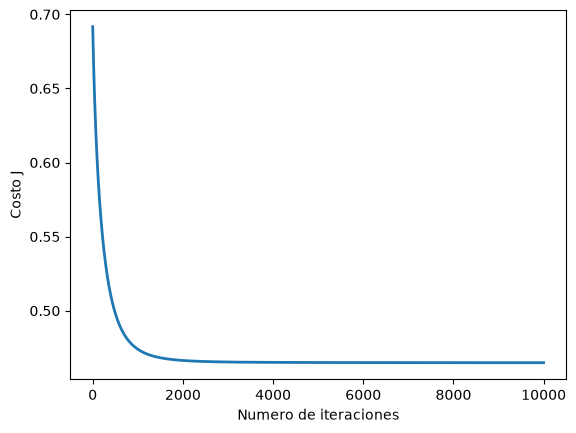

In [77]:
alpha = 0.01
num_iters = 10000

theta = np.zeros(X.shape[1])

theta, J_history = descensoGradiente(theta, X, y, alpha, num_iters)

pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

# Muestra los resultados del descenso por el gradiente
print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta)))

In [ ]:
m_test = len(X_test)
X_test_norm = (X_test - mu) / sigma
X_test_ready = np.concatenate([np.ones((m_test, 1)), X_test_norm], axis=1)

y_predicha = []

for x in X_test_ready:
    y_predicha.append(sigmoid(np.dot(x, theta)))

y_predicha = np.array(y_predicha)

y_umbral = (y_predicha >= 0.5).astype(int)

print("Primeras 10 probabilidades calculadas:", y_umbral[:10])
print("Primeras 10 predicciones (0 o 1):", y_predicha[:10])

precision = np.mean(y_umbral == y_test) * 100
print(f"\nPrecisión en el conjunto de prueba (Accuracy): {precision:.2f}%")


Primeras 10 probabilidades calculadas: [0 0 0 1 0 0 0 0 0 0]
Primeras 10 predicciones (0 o 1): [0.13669468 0.14827747 0.09253994 0.64129869 0.40221891 0.18664027
 0.10420007 0.12861189 0.20172308 0.06142941]

Precisión en el conjunto de prueba (Accuracy): 80.70%
